<a href="https://colab.research.google.com/github/Fata-Haidar/244107020108-Pembelajaran-Mesin/blob/main/JS10/Tugas_js10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Import library dan load dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target
print('Ukuran data:', X.shape)
print('Kelas:', dict(enumerate(data.target_names)))
display(X.head())
print(pd.Series(y).value_counts().rename(index={0:'malignant',1:'benign'}))

Ukuran data: (569, 30)
Kelas: {0: np.str_('malignant'), 1: np.str_('benign')}


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


target
benign       357
malignant    212
Name: count, dtype: int64


## 2. Bagi data train/test tanpa kebocoran informasi

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (455, 30) | Test: (114, 30)


## 3. Bangun dan latih dua model
`StandardScaler` dilatih terpisah di setiap pipeline **menggunakan train saja**.

In [3]:
models = {
    'Perceptron': make_pipeline(
        StandardScaler(), Perceptron(max_iter=1000, tol=1e-4, random_state=42)),
    'ANN MLP (32, 16)': make_pipeline(
        StandardScaler(), MLPClassifier(hidden_layer_sizes=(32, 16),
                                        activation='relu', max_iter=700,
                                        early_stopping=True, random_state=42,
                                        n_iter_no_change=30))
}
for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, 'berhasil dilatih.')

Perceptron berhasil dilatih.
ANN MLP (32, 16) berhasil dilatih.


## 4. Bandingkan metrik pengujian

,Accuracy,Precision (macro),Recall (macro),F1 (macro)
Model,,,,
Perceptron,0.956,0.948,0.960,0.954
"ANN MLP (32, 16)",0.921,0.912,0.938,0.918


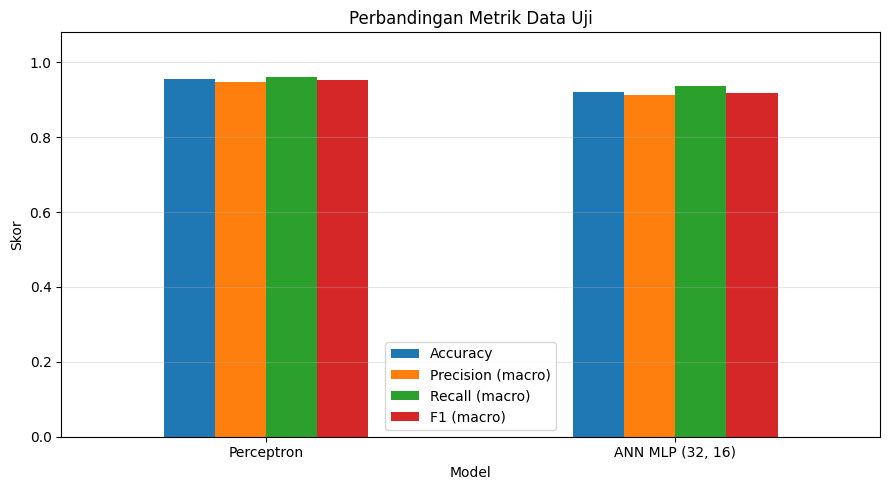

In [4]:
rows = []
for name, model in models.items():
    y_pred = model.predict(X_test)
    rows.append({'Model': name, 'Accuracy': accuracy_score(y_test, y_pred),
                 'Precision (macro)': precision_score(y_test, y_pred, average='macro', zero_division=0),
                 'Recall (macro)': recall_score(y_test, y_pred, average='macro', zero_division=0),
                 'F1 (macro)': f1_score(y_test, y_pred, average='macro', zero_division=0)})
result = pd.DataFrame(rows).set_index('Model')
display(result.style.format('{:.3f}'))
ax = result.plot.bar(rot=0, figsize=(9,5), ylim=(0,1.08))
ax.set_ylabel('Skor'); ax.set_title('Perbandingan Metrik Data Uji')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()

## 5. Confusion matrix untuk setiap model

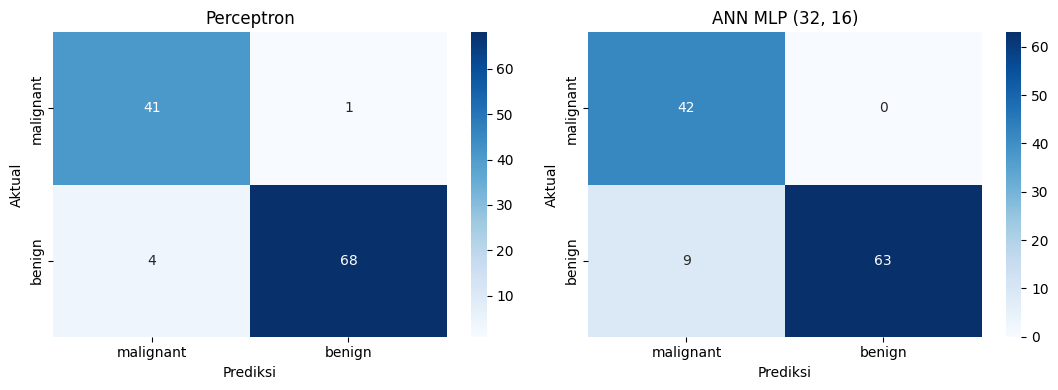

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, model) in zip(axes, models.items()):
    yp = model.predict(X_test)
    sns.heatmap(confusion_matrix(y_test, yp), annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=data.target_names, yticklabels=data.target_names)
    ax.set_title(name); ax.set_xlabel('Prediksi'); ax.set_ylabel('Aktual')
plt.tight_layout(); plt.show()

## 6. Eksperimen hyperparameter ANN
Ubah jumlah neuron pada hidden layer dan lihat dampaknya pada data uji. Data uji sebaiknya hanya digunakan untuk **evaluasi akhir**; pada penelitian serius pilih arsitektur melalui validation set atau cross-validation.

In [6]:
configs = [(8,), (16,), (32, 16)]
experiment = []
for config in configs:
    candidate = make_pipeline(StandardScaler(), MLPClassifier(
        hidden_layer_sizes=config, max_iter=700, random_state=42,
        early_stopping=True, n_iter_no_change=30))
    candidate.fit(X_train, y_train)
    experiment.append({'Hidden layers': str(config),
                       'Akurasi Train': candidate.score(X_train, y_train),
                       'Akurasi Test': candidate.score(X_test, y_test),
                       'Iterasi': candidate.named_steps['mlpclassifier'].n_iter_})
display(pd.DataFrame(experiment))

,Hidden layers,Akurasi Train,Akurasi Test,Iterasi
0,"(8,)",0.938462,0.947368,81
1,"(16,)",0.958242,0.956140,94
2,"(32, 16)",0.949451,0.921053,45


## 7. Kesimpulan otomatis dan jawaban diskusi

In [7]:
winner = result['F1 (macro)'].idxmax()
print('Model dengan F1-macro tertinggi pada uji ini:', winner)
print('Catatan: perbedaan kecil dapat bergantung random_state dan konfigurasi pelatihan.')
print('Hindari menyimpulkan satu model selalu terbaik hanya dari satu pembagian data.')

Model dengan F1-macro tertinggi pada uji ini: Perceptron
Catatan: perbedaan kecil dapat bergantung random_state dan konfigurasi pelatihan.
Hindari menyimpulkan satu model selalu terbaik hanya dari satu pembagian data.
